# 15 - Crowdedness at the Campus Gym Kaggle

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("15-gym_crowdedness.csv")

In [3]:
df.head()

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


In [6]:
df.isnull().sum()

number_people           0
date                    0
timestamp               0
day_of_week             0
is_weekend              0
is_holiday              0
temperature             0
is_start_of_semester    0
is_during_semester      0
month                   0
hour                    0
dtype: int64

In [12]:
df.shape

(62184, 11)

In [13]:
df.columns

Index(['number_people', 'date', 'timestamp', 'day_of_week', 'is_weekend',
       'is_holiday', 'temperature', 'is_start_of_semester',
       'is_during_semester', 'month', 'hour'],
      dtype='object')

In [15]:
#bir date obj olarak görünüyor değiştirebiliriz tarih ile
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   number_people         62184 non-null  int64  
 1   date                  62184 non-null  object 
 2   timestamp             62184 non-null  int64  
 3   day_of_week           62184 non-null  int64  
 4   is_weekend            62184 non-null  int64  
 5   is_holiday            62184 non-null  int64  
 6   temperature           62184 non-null  float64
 7   is_start_of_semester  62184 non-null  int64  
 8   is_during_semester    62184 non-null  int64  
 9   month                 62184 non-null  int64  
 10  hour                  62184 non-null  int64  
dtypes: float64(1), int64(9), object(1)
memory usage: 5.2+ MB


In [16]:
df.describe()

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
count,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000
mean,29.072543,45799.437958,2.982504,0.282870,0.002573,58.557108,0.078831,0.660218,7.439824,12.236460
std,22.689026,24211.275891,1.996825,0.450398,0.050660,6.316396,0.269476,0.473639,3.445069,6.717631
min,0.000000,0.000000,0.000000,0.000000,0.000000,38.140000,0.000000,0.000000,1.000000,0.000000
25%,9.000000,26624.000000,1.000000,0.000000,0.000000,55.000000,0.000000,0.000000,5.000000,7.000000
50%,28.000000,46522.500000,3.000000,0.000000,0.000000,58.340000,0.000000,1.000000,8.000000,12.000000
75%,43.000000,66612.000000,5.000000,1.000000,0.000000,62.280000,0.000000,1.000000,10.000000,18.000000
max,145.000000,86399.000000,6.000000,1.000000,1.000000,87.170000,1.000000,1.000000,12.000000,23.000000


In [17]:
df["date"]=pd.to_datetime(df["date"],utc=True)

In [18]:
df.head()

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-15 00:00:11+00:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-15 00:20:14+00:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-15 00:30:15+00:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-15 00:40:16+00:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-15 00:50:17+00:00,64217,4,0,0,71.76,0,0,8,17


In [19]:
df.info()
#çevrildi

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   number_people         62184 non-null  int64              
 1   date                  62184 non-null  datetime64[ns, UTC]
 2   timestamp             62184 non-null  int64              
 3   day_of_week           62184 non-null  int64              
 4   is_weekend            62184 non-null  int64              
 5   is_holiday            62184 non-null  int64              
 6   temperature           62184 non-null  float64            
 7   is_start_of_semester  62184 non-null  int64              
 8   is_during_semester    62184 non-null  int64              
 9   month                 62184 non-null  int64              
 10  hour                  62184 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(1), int64(9)
memory usage: 5.2 M

In [20]:
df["date"]

0       2015-08-15 00:00:11+00:00
1       2015-08-15 00:20:14+00:00
2       2015-08-15 00:30:15+00:00
3       2015-08-15 00:40:16+00:00
4       2015-08-15 00:50:17+00:00
                   ...           
62179   2017-03-19 01:42:28+00:00
62180   2017-03-19 01:52:35+00:00
62181   2017-03-19 02:02:40+00:00
62182   2017-03-19 02:12:47+00:00
62183   2017-03-19 02:22:51+00:00
Name: date, Length: 62184, dtype: datetime64[ns, UTC]

In [22]:
df["year"]=df["date"].dt.year
#sadece ayları,yılları,günleri,saatleri getirebiliyoruz.
#zten ayarlamıslar dt de bizde yenı bir kolon açıp year ile almamız yeterli

In [24]:
df.head()

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,2015-08-15 00:00:11+00:00,61211,4,0,0,71.76,0,0,8,17,2015
1,45,2015-08-15 00:20:14+00:00,62414,4,0,0,71.76,0,0,8,17,2015
2,40,2015-08-15 00:30:15+00:00,63015,4,0,0,71.76,0,0,8,17,2015
3,44,2015-08-15 00:40:16+00:00,63616,4,0,0,71.76,0,0,8,17,2015
4,45,2015-08-15 00:50:17+00:00,64217,4,0,0,71.76,0,0,8,17,2015


In [25]:
df["year"].unique()

array([2015, 2016, 2017], dtype=int32)

In [26]:
df.drop("date",axis=1,inplace=True)

In [27]:
df.head()

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,61211,4,0,0,71.76,0,0,8,17,2015
1,45,62414,4,0,0,71.76,0,0,8,17,2015
2,40,63015,4,0,0,71.76,0,0,8,17,2015
3,44,63616,4,0,0,71.76,0,0,8,17,2015
4,45,64217,4,0,0,71.76,0,0,8,17,2015


<Axes: xlabel='number_people', ylabel='Count'>

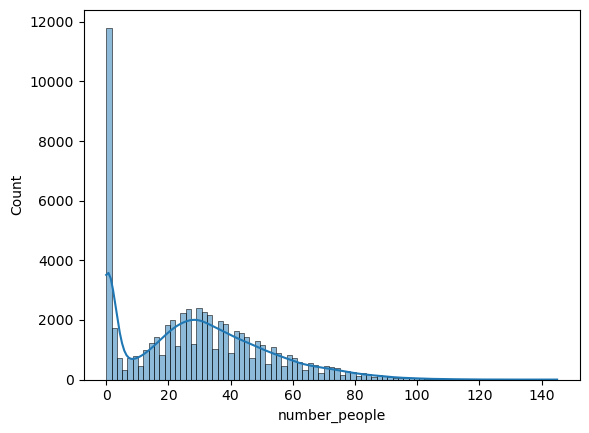

In [29]:
#hedef değişkenleri tanıma
sns.histplot(data=df,x="number_people",kde=True)


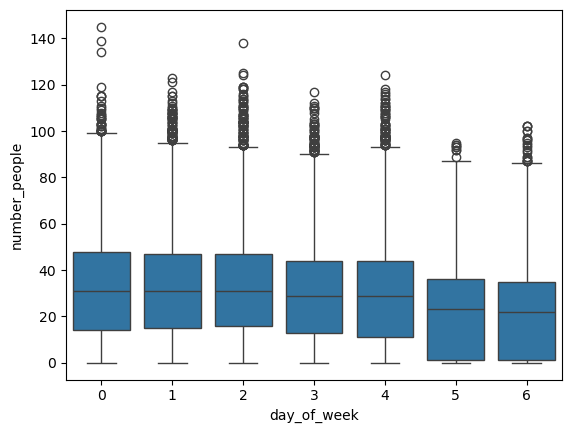

In [34]:
sns.boxplot(data=df,x="day_of_week",y="number_people")
plt.show()


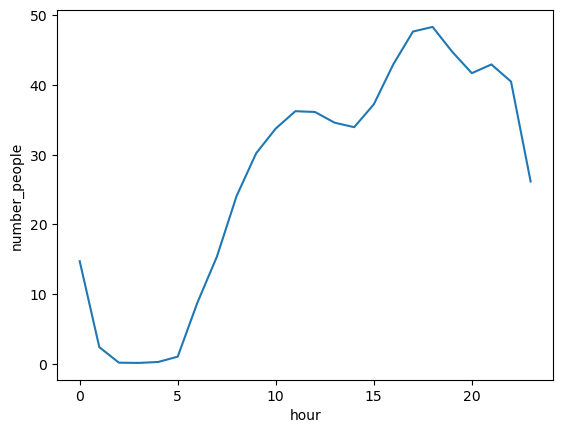

In [31]:
sns.lineplot(data=df,
            x="hour",
            y="number_people",
            estimator="mean",
            errorbar=None)
plt.show()

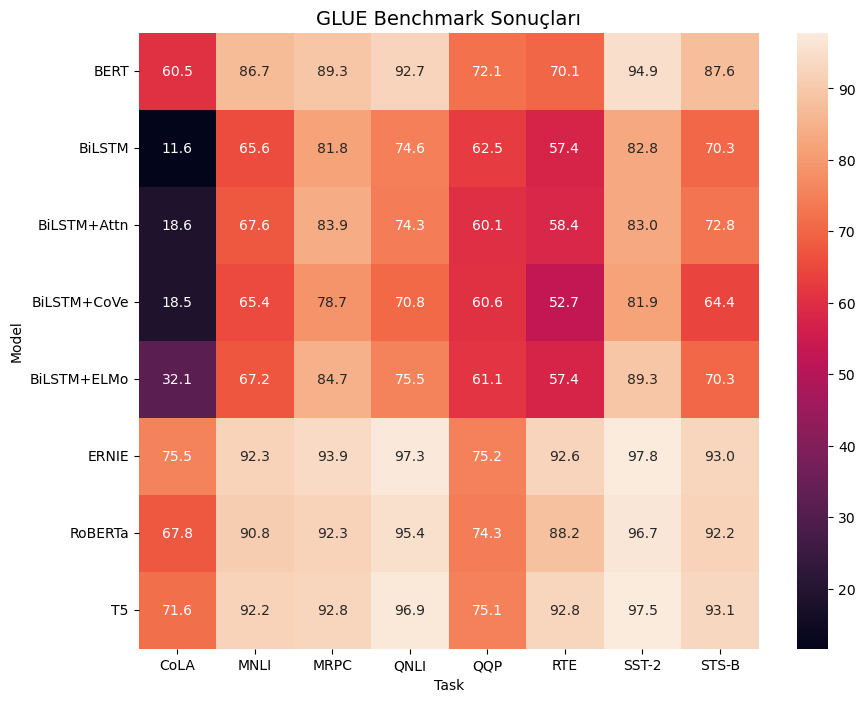

In [65]:
glue = sns.load_dataset("glue").pivot(index="Model", columns="Task", values="Score")
plt.figure(figsize=(10, 8))
sns.heatmap(glue,annot=True,fmt=".1f")
plt.title("GLUE Benchmark Sonuçları", fontsize=14)
plt.show()

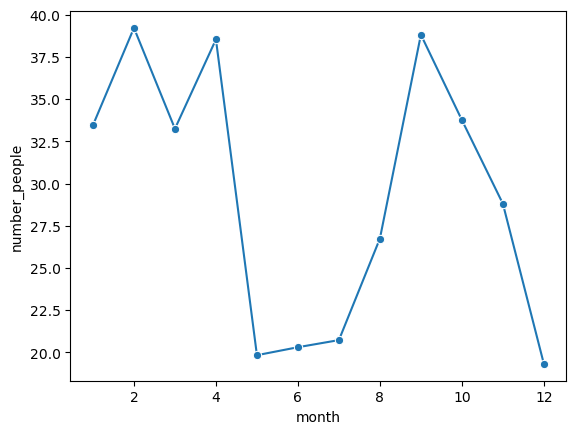

In [71]:
sns.lineplot(
    data=df,
    x="month",
    y="number_people",
    estimator="mean",
    errorbar=None,
    marker="o"
)
plt.show()

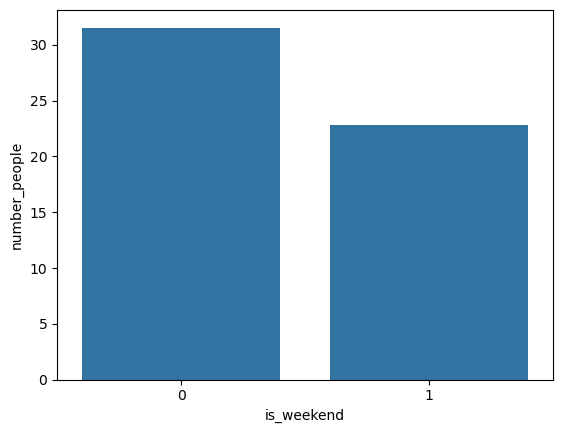

In [72]:
sns.barplot(
    data=df,
    x="is_weekend",
    y="number_people",
    errorbar=None
)
plt.show()

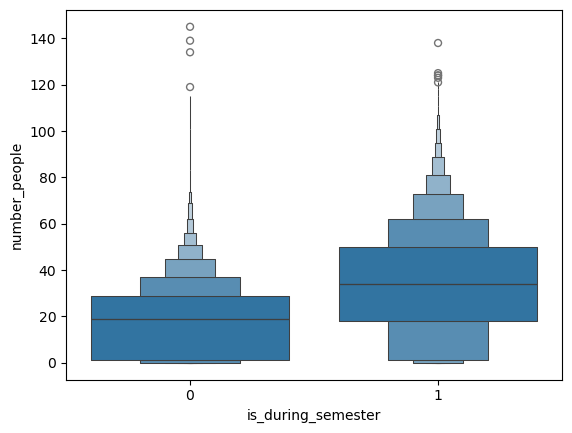

In [77]:
sns.boxenplot(data=df,x="is_during_semester",y="number_people")
plt.show()

<Axes: xlabel='temperature', ylabel='number_people'>

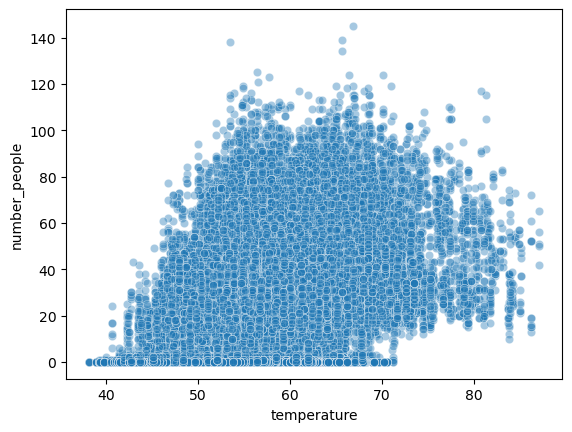

In [78]:
sns.scatterplot(
    data=df,
    x="temperature",
    y="number_people",
    alpha=0.4
)

<Axes: >

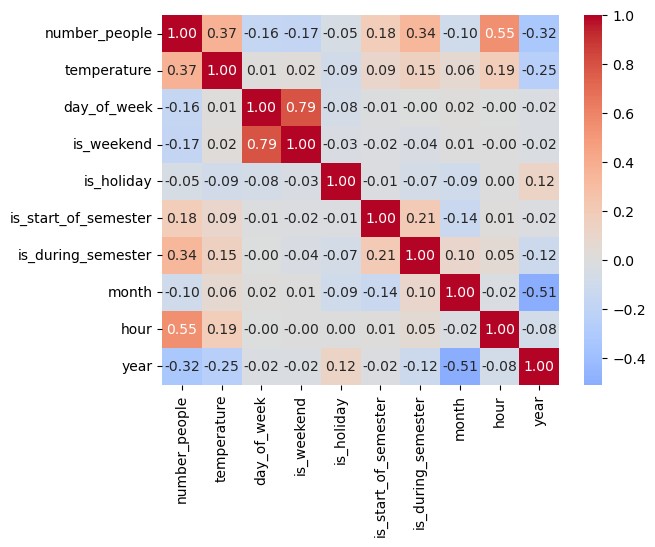

In [79]:
numeric_cols = [
    "number_people",
    "temperature",
    "day_of_week",
    "is_weekend",
    "is_holiday",
    "is_start_of_semester",
    "is_during_semester",
    "month",
    "hour",
    "year"
]

corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

In [80]:
df.drop("timestamp",axis=1,inplace=True)

In [81]:
df.head()

,number_people,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,4,0,0,71.76,0,0,8,17,2015
1,45,4,0,0,71.76,0,0,8,17,2015
2,40,4,0,0,71.76,0,0,8,17,2015
3,44,4,0,0,71.76,0,0,8,17,2015
4,45,4,0,0,71.76,0,0,8,17,2015


In [82]:
X = df.drop("number_people",axis=1)
y=df["number_people"]

In [83]:
from sklearn.model_selection import train_test_split

In [84]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=15)

In [85]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [86]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [101]:
def calculate_model_metrics(true,predicted):
    mae = mean_absolute_error(true,predicted)
    mse=mean_squared_error(true,predicted)
    rmse = np.sqrt(mean_squared_error(true,predicted))
    r2_square= r2_score(true,predicted)
    return mae,rmse,r2_square

In [102]:
models = {
    "Linear Regression" : LinearRegression(),
    "Lasso" : Lasso(),
    "Ridge":Ridge(),
    "KNeighborsRegressor":KNeighborsRegressor(),
    "DecisionTreeRegressor":DecisionTreeRegressor(),
    "RandomForestRegressor":RandomForestRegressor()
}

In [103]:
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train,y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae,model_train_rmse,model_train_r2=calculate_model_metrics(y_train,y_train_pred)
    model_test_mae,model_test_rmse,model_test_r2=calculate_model_metrics(y_test,y_test_pred)

    print(list(models.values())[i])
    
    print("Evalutaion for training set")
    print("RMSE",model_train_rmse)
    print("Mean Absolute Error",model_train_mae)
    print("R2",model_train_r2)

    print("-----------")
    print("Evalutaion for TEST set")
    print("RMSE",model_test_rmse)
    print("Mean Absolute Error",model_test_mae)
    print("R2",model_test_r2)

    print("----------")
    print("\n")

LinearRegression()
Evalutaion for training set
RMSE 14.323063056411158
Mean Absolute Error 10.736278545598694
R2 0.5990450245502597
-----------
Evalutaion for TEST set
RMSE 14.428398933399553
Mean Absolute Error 10.772974414744665
R2 0.6011719749263944
----------


Lasso()
Evalutaion for training set
RMSE 14.569436612540299
Mean Absolute Error 10.949098595750266
R2 0.5851325940338806
-----------
Evalutaion for TEST set
RMSE 14.689069069323276
Mean Absolute Error 10.968873724694198
R2 0.5866309750797496
----------


Ridge()
Evalutaion for training set
RMSE 14.323063062879449
Mean Absolute Error 10.736288598189763
R2 0.5990450241881172
-----------
Evalutaion for TEST set
RMSE 14.428400979234796
Mean Absolute Error 10.772983010429632
R2 0.6011718618249351
----------


KNeighborsRegressor()
Evalutaion for training set
RMSE 5.540343589912466
Mean Absolute Error 3.7182043741959196
R2 0.9400074673173622
-----------
Evalutaion for TEST set
RMSE 7.325426535564931
Mean Absolute Error 4.934948542

In [104]:
#multiple tuning

In [105]:
#hyperparameter tuning

knn_params = {"n_neighbors" : [2,3,10,20,40,50]}
rf_params = {
        "max_depth" : [5,8,10,15,None],
        "max_features" : ["sqrt", "log2", 5, 7, 10],
        "min_samples_split" : [2, 8, 12, 20],
        "n_estimators" : [100, 200, 500, 1000]
}



In [106]:
from sklearn.model_selection import RandomizedSearchCV


In [107]:
randomcv_models = [
    ("KNN", KNeighborsRegressor(), knn_params),
    ("RF", RandomForestRegressor(), rf_params)
        ]

In [108]:
for name, model, params in randomcv_models:
    randomcv = RandomizedSearchCV(estimator=model, param_distributions=params, n_iter = 100, cv = 3, n_jobs = -1)
    randomcv.fit(X_train, y_train)
    print("best params for :", name, randomcv.best_params_)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 6 is smaller than n_iter=100. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params for : KNN {'n_neighbors': 2}


/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


best params for : RF {'n_estimators': 1000, 'min_samples_split': 2, 'max_features': 5, 'max_depth': None}


In [109]:

models = {
    "K-Neighbors Regressor"  : KNeighborsRegressor(n_neighbors=2),
    "Random Forest Regressor" : RandomForestRegressor(n_estimators=500,
                                                     min_samples_split=2,
                                                      max_features=7,
                                                      max_depth = None)
}

In [110]:

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae, model_train_rmse, model_train_r2 = calculate_model_metrics(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = calculate_model_metrics(y_test, y_test_pred)

    print(list(models.values())[i])

    print("Evaluation for Training Set")
    print("RMSE :", model_train_rmse)
    print("Mean Absolute Error :", model_train_mae)
    print("R2 Score :", model_train_r2)

    print("-----------------------------")
    
    print("Evaluation for Test Set")
    print("RMSE :", model_test_rmse)
    print("Mean Absolute Error :", model_test_mae)
    print("R2 Score :", model_test_r2)

    print("-----------------------------")
    print("\n")

KNeighborsRegressor(n_neighbors=2)
Evaluation for Training Set
RMSE : 5.3876119330814225
Mean Absolute Error : 3.490052380077192
R2 Score : 0.9432695260864069
-----------------------------
Evaluation for Test Set
RMSE : 6.951656299053595
Mean Absolute Error : 4.673456260720411
R2 Score : 0.9074181258376348
-----------------------------


RandomForestRegressor(max_features=7, n_estimators=500)
Evaluation for Training Set
RMSE : 4.65691305568316
Mean Absolute Error : 3.1590406547078453
R2 Score : 0.9576142317974712
-----------------------------
Evaluation for Test Set
RMSE : 6.466098365847616
Mean Absolute Error : 4.326683234956674
R2 Score : 0.9198997265557137
-----------------------------


